<a href="https://colab.research.google.com/github/tejalkv0/Responsible-AI-Model-Interpretation/blob/main/responsible_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4: Responsible AI & Model Interpretation
## Fairness, bias and explainability of an income-prediction model

**Goal:** analyse fairness, bias and explainability of one model, using SHAP, and propose mitigation.

**Dataset:** UCI **Adult / Census Income** (48,842 people, ~14 features). The model predicts whether income is **>50K**. It is the standard benchmark for fairness work because it contains sensitive attributes (**sex** and **race**).
*(Loaded automatically from OpenML. Colab has internet access. If the download fails, the notebook falls back to a clearly labelled synthetic stand-in so the code still runs.)*

| Requirement | Where |
|---|---|
| Feature importances + SHAP/LIME local explanations | Sections 4–5 |
| Bias check across sensitive groups | Sections 6–7 |
| Practical mitigation steps (implemented and measured) | Section 8 |
| Interpretation plots + analysis; short write-up | All plots saved as PNG; Section 10 generates `REPORT.md` with your numbers |

**Run in Google Colab:** Runtime → Run all (CPU is fine; about 3–6 minutes).

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)

## 2. Load the data
Sensitive attributes audited: **sex** and **race**.

In [2]:
def make_synthetic_adult(n=20000, seed=SEED):
    """Offline stand-in with the same columns as Adult and a deliberately injected sex effect. Only used if the download fails."""
    rng = np.random.RandomState(seed)
    sex = rng.choice(["Male", "Female"], n, p=[0.67, 0.33])
    race = rng.choice(["White", "Black", "Asian-Pac-Islander", "Amer-Indian-Eskimo", "Other"], n, p=[0.85, 0.10, 0.03, 0.01, 0.01])
    age = np.clip(rng.normal(39, 13, n), 17, 90).round()
    edu = np.clip(rng.normal(10, 2.5, n), 1, 16).round()
    hours = np.clip(rng.normal(40, 11, n), 1, 99).round()
    married = rng.rand(n) < np.where(sex == "Male", 0.5, 0.3)
    marital = np.where(married, "Married-civ-spouse", rng.choice(["Never-married", "Divorced", "Separated", "Widowed"], n, p=[.5, .3, .12, .08]))
    relationship = np.where(married, np.where(sex == "Male", "Husband", "Wife"), rng.choice(["Not-in-family", "Own-child", "Unmarried"], n))
    occupation = np.where(sex == "Male",
                          rng.choice(["Craft-repair", "Exec-managerial", "Prof-specialty", "Sales", "Transport-moving"], n),
                          rng.choice(["Adm-clerical", "Exec-managerial", "Prof-specialty", "Sales", "Other-service"], n))
    workclass = rng.choice(["Private", "Self-emp-not-inc", "Local-gov", "State-gov"], n, p=[.75, .1, .08, .07])
    cap_gain = np.where(rng.rand(n) < 0.08, rng.exponential(6000, n), 0).round()
    cap_loss = np.where(rng.rand(n) < 0.05, rng.normal(1800, 300, n), 0).round()
    country = rng.choice(["United-States", "Mexico", "India", "Other"], n, p=[.9, .03, .02, .05])
    logit = (-8.6 + 0.35*edu + 0.03*age + 0.04*hours + 1.2*married + 0.9*(sex == "Male")
             + 0.0002*cap_gain + 0.8*(occupation == "Exec-managerial"))
    y = rng.rand(n) < 1 / (1 + np.exp(-logit))
    return pd.DataFrame({"age": age, "workclass": workclass, "fnlwgt": 1, "education": "x", "education-num": edu,
                         "marital-status": marital, "occupation": occupation, "relationship": relationship,
                         "race": race, "sex": sex, "capital-gain": cap_gain, "capital-loss": cap_loss,
                         "hours-per-week": hours, "native-country": country,
                         "income": np.where(y, ">50K", "<=50K")})

try:
    from sklearn.datasets import fetch_openml
    df = fetch_openml("adult", version=2, as_frame=True).frame.rename(columns={"class": "income"})
    DATA_SOURCE = "UCI Adult (OpenML)"
except Exception as e:
    print("!! Could not download Adult dataset:", type(e).__name__)
    print("!! Falling back to SYNTHETIC data. Do NOT report these numbers as real Adult results.")
    df = make_synthetic_adult(); DATA_SOURCE = "SYNTHETIC stand-in"

print("Data source:", DATA_SOURCE, "| shape:", df.shape)

Data source: UCI Adult (OpenML) | shape: (48842, 15)


## 3. Preprocessing and EDA
- Target: `income > 50K` → 1.
- Dropped `fnlwgt` (a survey weight) and `education` (duplicate of `education-num`); `native-country` is grouped to US / Other.
- Missing values (marked `?` in the original data) are imputed with the most frequent category inside the model pipeline.
- Data is split **60% train / 20% validation / 20% test**, stratified by outcome and sex. The validation set is used later to tune mitigation thresholds; the test set is for final reporting.

train=29304  val=9769  test=9769  | overall share earning >50K: 0.239


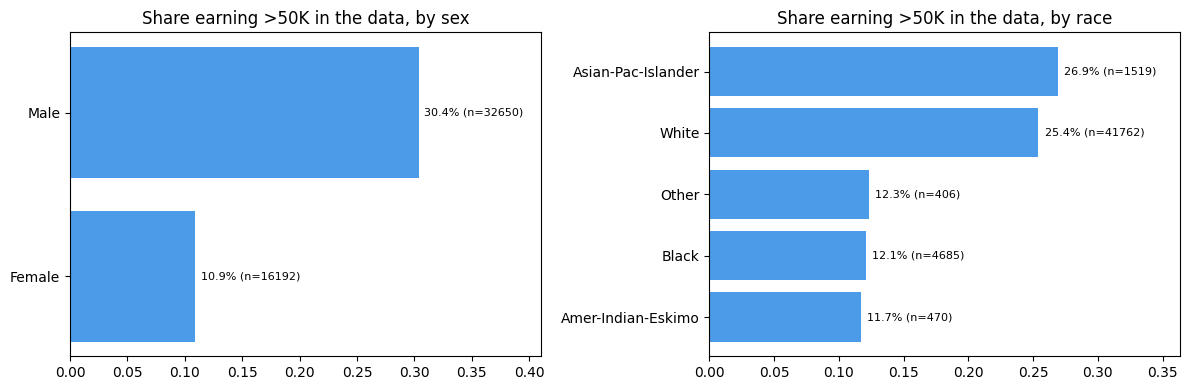

In [3]:
df = df.copy()
df["income"] = df["income"].astype(str).str.strip().str.startswith(">50K").astype(int)
cat_all = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
for c in cat_all: df[c] = df[c].astype(object)
df["native-country"] = np.where(df["native-country"] == "United-States", "United-States", "Other")
df = df.drop(columns=["fnlwgt", "education"])

NUM_COLS = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CAT_COLS = cat_all
SENSITIVE = ["sex", "race"]
for c in NUM_COLS: df[c] = pd.to_numeric(df[c])

X, y = df.drop(columns="income"), df["income"]
strat = y.astype(str) + "_" + X["sex"].astype(str)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=strat, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=strat.loc[X_tmp.index], random_state=SEED)
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}  | overall share earning >50K: {y.mean():.3f}")

# Base rates in the DATA, before any model is involved
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, SENSITIVE):
    t = df.groupby(col)["income"].agg(["mean", "size"]).sort_values("mean")
    a.barh(t.index, t["mean"], color="#4c9be8")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])): a.text(m + 0.005, i, f"{m:.1%} (n={n})", va="center", fontsize=8)
    a.set_xlim(0, t["mean"].max() * 1.35); a.set_title(f"Share earning >50K in the data, by {col}")
plt.tight_layout(); plt.savefig("eda_base_rates.png", dpi=150); plt.show()

## 4. Baseline model and global feature importance
A Random Forest inside a scikit-learn pipeline (one-hot encoding of categorical features). Sensitive attributes are **included** in this baseline so we can see how much the model relies on them.

In [4]:
def build_model(drop_sensitive=False):
    cats = [c for c in CAT_COLS if not (drop_sensitive and c in SENSITIVE)]
    prep = ColumnTransformer([
        ("num", "passthrough", NUM_COLS),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats)],
        sparse_threshold=0)
    clf = RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    return Pipeline([("prep", prep), ("clf", clf)])

base_model = build_model().fit(X_train, y_train)
base_score_test = base_model.predict_proba(X_test)[:, 1]
base_pred_test = (base_score_test >= 0.5).astype(int)
print(f"Baseline  accuracy={accuracy_score(y_test, base_pred_test):.3f}  F1={f1_score(y_test, base_pred_test):.3f}  ROC-AUC={roc_auc_score(y_test, base_score_test):.3f}")

Baseline  accuracy=0.866  F1=0.672  ROC-AUC=0.920


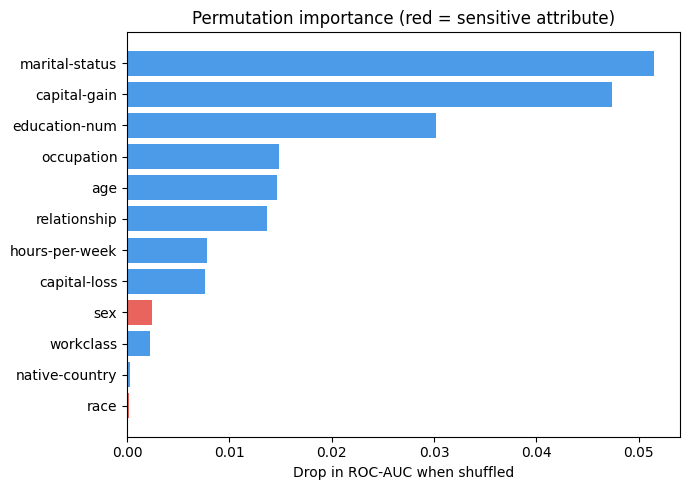

marital-status    0.0515
capital-gain      0.0474
education-num     0.0302
occupation        0.0149
age               0.0147
relationship      0.0137
hours-per-week    0.0078
capital-loss      0.0077
sex               0.0025
workclass         0.0022
native-country    0.0003
race              0.0002


In [5]:
# Global importance: permutation importance on the ORIGINAL columns (shuffle one column at a time, measure the drop in ROC-AUC)
sub = X_test.sample(min(5000, len(X_test)), random_state=SEED)
pi = permutation_importance(base_model, sub, y_test.loc[sub.index], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

top = perm_imp.head(12).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=["#e8645c" if c in SENSITIVE else "#4c9be8" for c in top.index])
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title("Permutation importance (red = sensitive attribute)")
plt.tight_layout(); plt.savefig("permutation_importance.png", dpi=150); plt.show()
print(perm_imp.round(4).to_string())

## 5. Local and global explanations with SHAP
SHAP assigns each feature a contribution (positive or negative) to each individual prediction. The **summary plot** shows global patterns; the **waterfall plots** explain individual people.

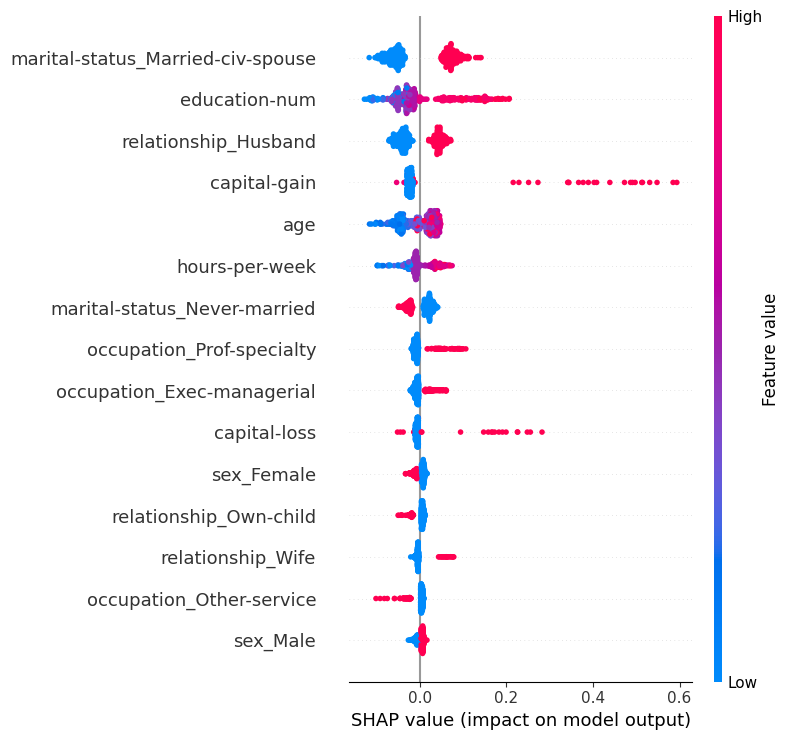

In [6]:
# [SHAP]
import subprocess, sys
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

prep, rf = base_model.named_steps["prep"], base_model.named_steps["clf"]
feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Xs = X_test.sample(500, random_state=SEED)
Xs_t = pd.DataFrame(prep.transform(Xs), columns=feat_names)

explainer = shap.TreeExplainer(rf)
sv = explainer(Xs_t, check_additivity=False)
if sv.values.ndim == 3: sv = sv[:, :, 1]          # keep the ">50K" class

plt.figure(); shap.summary_plot(sv.values, Xs_t, show=False, max_display=15)
plt.tight_layout(); plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

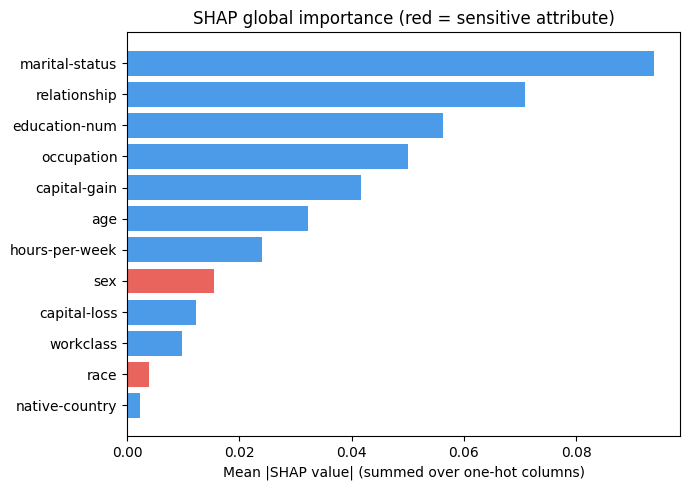

In [7]:
# [SHAP]
# SHAP contribution summed per ORIGINAL feature (one-hot columns grouped back together)
def original_col(name):
    for c in sorted(CAT_COLS, key=len, reverse=True):
        if name.startswith(c + "_"): return c
    return name
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=feat_names)
shap_by_feature = mean_abs.groupby(original_col).sum().sort_values(ascending=False)

top = shap_by_feature.head(12).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=["#e8645c" if c in SENSITIVE else "#4c9be8" for c in top.index])
plt.xlabel("Mean |SHAP value| (summed over one-hot columns)"); plt.title("SHAP global importance (red = sensitive attribute)")
plt.tight_layout(); plt.savefig("shap_global_importance.png", dpi=150); plt.show()


high_confidence_over_50K: predicted P(>50K) = 0.98 | actual = >50K
{'age': 52, 'workclass': 'Self-emp-inc', 'education-num': 15, 'marital-status': 'Married-civ-spouse', 'occupation': 'Prof-specialty', 'relationship': 'Husband', 'race': 'White', 'sex': 'Male', 'capital-gain': 15024, 'capital-loss': 0, 'hours-per-week': 60, 'native-country': 'United-States'}


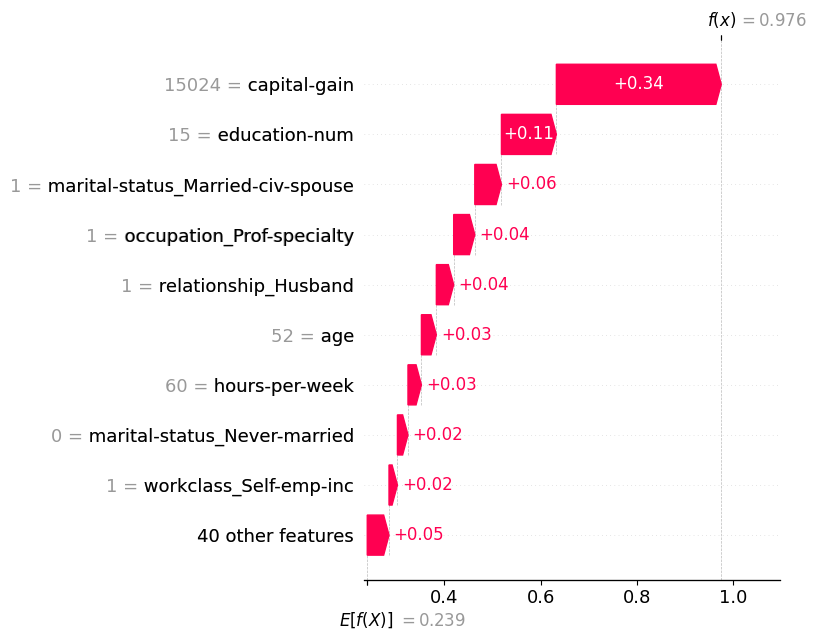


high_confidence_under_50K: predicted P(>50K) = 0.00 | actual = <=50K
{'age': 17, 'workclass': 'Private', 'education-num': 6, 'marital-status': 'Never-married', 'occupation': 'Other-service', 'relationship': 'Own-child', 'race': 'White', 'sex': 'Female', 'capital-gain': 0, 'capital-loss': 0, 'hours-per-week': 30, 'native-country': 'United-States'}


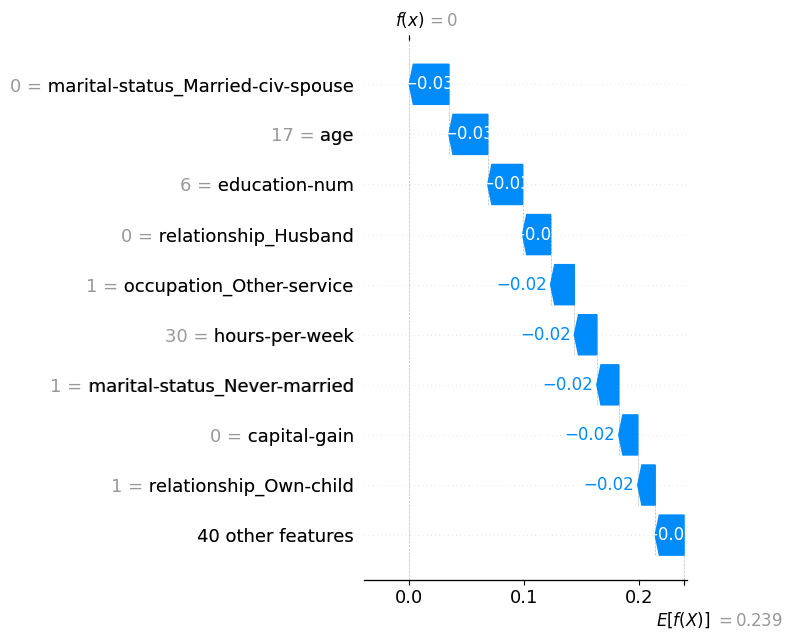


borderline: predicted P(>50K) = 0.50 | actual = >50K
{'age': 37, 'workclass': 'Private', 'education-num': 11, 'marital-status': 'Married-civ-spouse', 'occupation': 'Prof-specialty', 'relationship': 'Husband', 'race': 'White', 'sex': 'Male', 'capital-gain': 0, 'capital-loss': 0, 'hours-per-week': 48, 'native-country': 'United-States'}


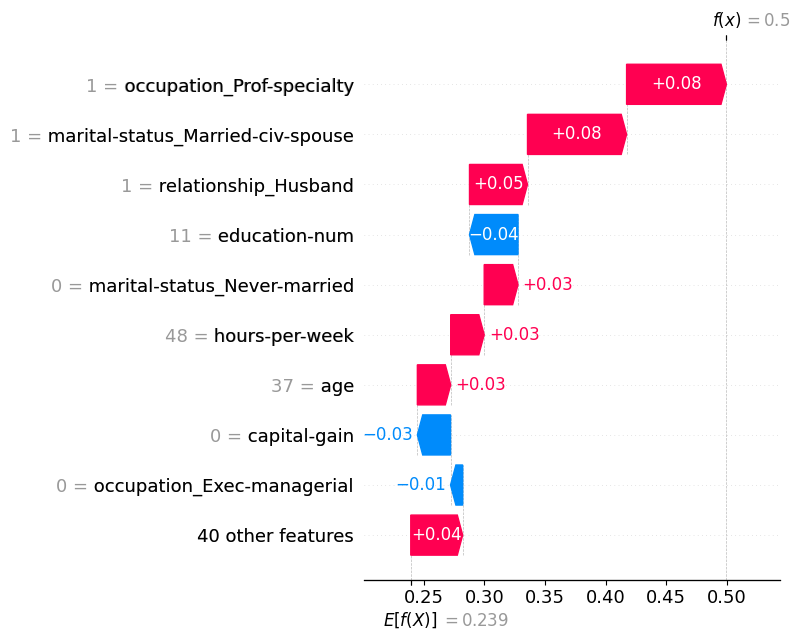

In [8]:
# [SHAP]
# Local explanations: most confident >50K, most confident <=50K, and a borderline case
probs = rf.predict_proba(Xs_t.values)[:, 1]
picks = {"high_confidence_over_50K": int(np.argmax(probs)), "high_confidence_under_50K": int(np.argmin(probs)),
         "borderline": int(np.argmin(np.abs(probs - 0.5)))}
for label, i in picks.items():
    print(f"\n{label}: predicted P(>50K) = {probs[i]:.2f} | actual = {'>50K' if y_test.loc[Xs.index[i]] else '<=50K'}")
    print(Xs.iloc[i].to_dict())
    plt.figure(); shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.tight_layout(); plt.savefig(f"shap_waterfall_{label}.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Fairness metrics
For each sensitive group we compute:
- **Selection rate**: share predicted >50K
- **TPR (recall)**: among people who truly earn >50K, share the model finds
- **FPR**: among people who truly earn ≤50K, share wrongly predicted >50K

Group-gap metrics:
- **Demographic parity difference** = max − min selection rate (0 = equal)
- **Disparate impact ratio** = min / max selection rate (the "four-fifths rule" flags ratios < 0.80)
- **Equal opportunity difference** = max − min TPR
- **Equalized-odds gap** = larger of the TPR gap and FPR gap

Groups with fewer than 50 test samples are excluded from the gap metrics because their rates are too noisy.

In [9]:
MIN_N = 50

def group_report(y_true, y_pred, groups):
    y_true, y_pred, groups = np.asarray(y_true), np.asarray(y_pred), np.asarray(groups)
    rows = {}
    for g in np.unique(groups):
        m = groups == g; yt, yp = y_true[m], y_pred[m]
        rows[g] = {"n": int(m.sum()), "base_rate": yt.mean(), "selection_rate": yp.mean(),
                   "TPR": (yp[yt == 1] == 1).mean() if (yt == 1).any() else np.nan,
                   "FPR": (yp[yt == 0] == 1).mean() if (yt == 0).any() else np.nan,
                   "accuracy": (yp == yt).mean()}
    return pd.DataFrame(rows).T

def fairness_summary(y_true, y_pred, groups):
    r = group_report(y_true, y_pred, groups); r = r[r["n"] >= MIN_N]
    return {"dp_diff": r["selection_rate"].max() - r["selection_rate"].min(),
            "dp_ratio": r["selection_rate"].min() / max(r["selection_rate"].max(), 1e-9),
            "eo_diff": r["TPR"].max() - r["TPR"].min(),
            "eodds_gap": max(r["TPR"].max() - r["TPR"].min(), r["FPR"].max() - r["FPR"].min())}

sex_test, race_test = X_test["sex"].values, X_test["race"].values
rep_sex  = group_report(y_test, base_pred_test, sex_test)
rep_race = group_report(y_test, base_pred_test, race_test)
print("=== Baseline model, by SEX ==="); print(rep_sex.round(3).to_string())
print("\n=== Baseline model, by RACE ==="); print(rep_race.round(3).to_string())
base_fair_sex, base_fair_race = fairness_summary(y_test, base_pred_test, sex_test), fairness_summary(y_test, base_pred_test, race_test)
print("\nSex gaps :", {k: round(v, 3) for k, v in base_fair_sex.items()})
print("Race gaps:", {k: round(v, 3) for k, v in base_fair_race.items()})

=== Baseline model, by SEX ===
             n  base_rate  selection_rate    TPR    FPR  accuracy
Female  3239.0      0.109           0.068  0.503  0.015     0.933
Male    6530.0      0.304           0.219  0.586  0.059     0.833

=== Baseline model, by RACE ===
                         n  base_rate  selection_rate    TPR    FPR  accuracy
Amer-Indian-Eskimo   101.0      0.069           0.069  0.857  0.011     0.980
Asian-Pac-Islander   293.0      0.242           0.205  0.662  0.059     0.874
Black                865.0      0.141           0.075  0.434  0.016     0.906
Other                 82.0      0.110           0.061  0.333  0.027     0.902
White               8428.0      0.253           0.180  0.579  0.045     0.860

Sex gaps : {'dp_diff': 0.151, 'dp_ratio': 0.31, 'eo_diff': 0.083, 'eodds_gap': 0.083}
Race gaps: {'dp_diff': 0.144, 'dp_ratio': 0.298, 'eo_diff': 0.524, 'eodds_gap': 0.524}


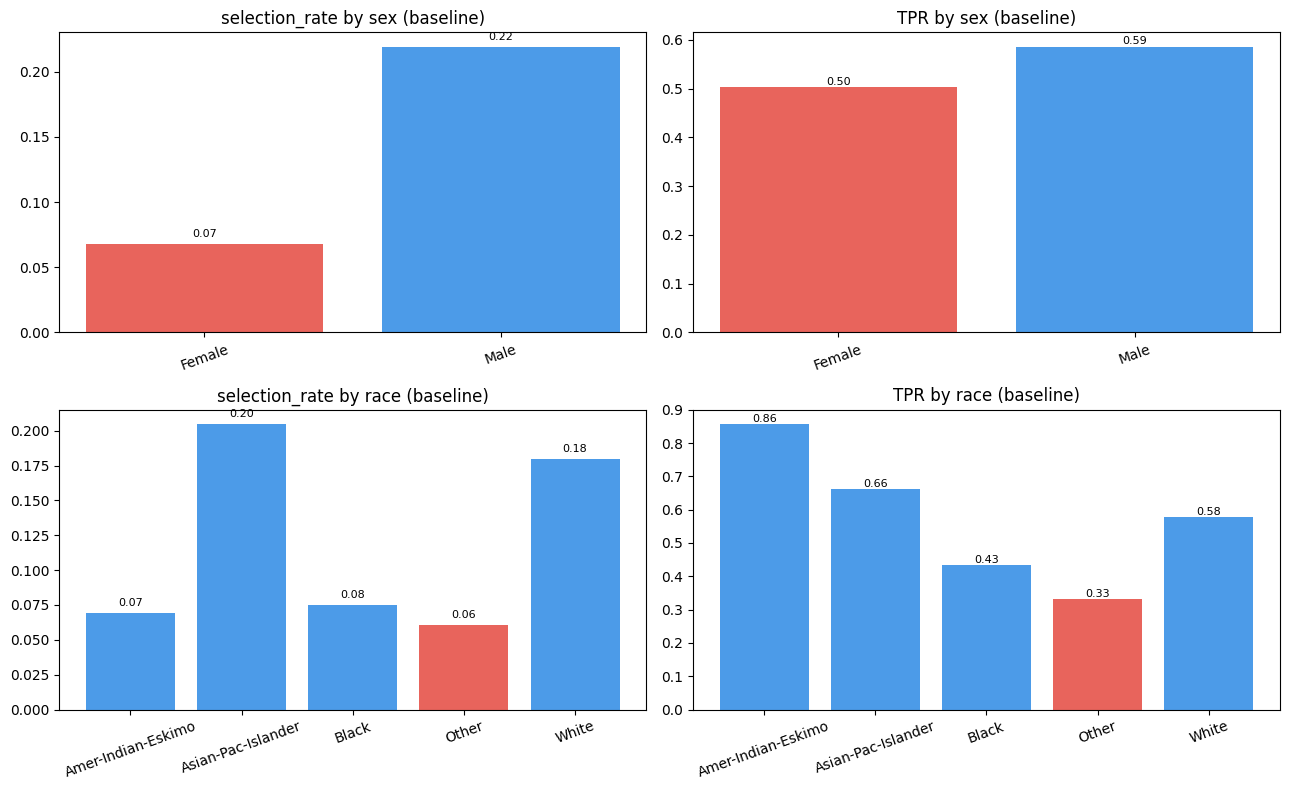

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for r, (rep, col) in enumerate([(rep_sex, "sex"), (rep_race, "race")]):
    rep = rep[rep["n"] >= MIN_N]
    for c, metric in enumerate(["selection_rate", "TPR"]):
        ax[r, c].bar(rep.index, rep[metric], color=["#e8645c" if i == rep[metric].idxmin() else "#4c9be8" for i in rep.index])
        ax[r, c].set_title(f"{metric} by {col} (baseline)"); ax[r, c].tick_params(axis="x", rotation=20)
        for i, v in enumerate(rep[metric]): ax[r, c].text(i, v + 0.005, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("fairness_audit.png", dpi=150); plt.show()

## 7. Is removing the sensitive attributes enough? ("fairness through unawareness")
Two checks:
1. **Retrain without `sex` and `race`** and see whether the gaps shrink.
2. **Proxy test:** can `sex` be predicted from the *remaining* features? If yes, the information is still present through proxies (e.g. relationship, marital status, occupation, hours worked).

In [11]:
unaware = build_model(drop_sensitive=True).fit(X_train, y_train)
unaware_score_test = unaware.predict_proba(X_test)[:, 1]
unaware_pred_test = (unaware_score_test >= 0.5).astype(int)
unaware_fair_sex = fairness_summary(y_test, unaware_pred_test, sex_test)
print(f"Without sex/race: accuracy={accuracy_score(y_test, unaware_pred_test):.3f}")
print("Sex gaps (unaware):", {k: round(v, 3) for k, v in unaware_fair_sex.items()})

# Proxy test: predict sex from non-sensitive features
non_sens = [c for c in X.columns if c not in SENSITIVE]
proxy_prep = ColumnTransformer([("num", "passthrough", [c for c in NUM_COLS]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
     [c for c in CAT_COLS if c not in SENSITIVE])], sparse_threshold=0)
proxy_model = Pipeline([("prep", proxy_prep), ("clf", RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=5, n_jobs=-1, random_state=SEED))])
proxy_model.fit(X_train[non_sens], (X_train["sex"] == "Female").astype(int))
proxy_auc = roc_auc_score((X_test["sex"] == "Female").astype(int), proxy_model.predict_proba(X_test[non_sens])[:, 1])
print(f"\nProxy test: sex can be predicted from the remaining features with ROC-AUC = {proxy_auc:.3f} (0.5 = no leakage, 1.0 = perfect)")
sub2 = X_test.sample(min(3000, len(X_test)), random_state=SEED)
pp = permutation_importance(proxy_model, sub2[non_sens], (sub2["sex"] == "Female").astype(int), scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=-1)
proxy_top = pd.Series(pp.importances_mean, index=non_sens).sort_values(ascending=False).head(4)
print("Strongest proxies for sex:", ", ".join(proxy_top.index))

Without sex/race: accuracy=0.866
Sex gaps (unaware): {'dp_diff': 0.154, 'dp_ratio': 0.308, 'eo_diff': 0.09, 'eodds_gap': 0.09}

Proxy test: sex can be predicted from the remaining features with ROC-AUC = 0.931 (0.5 = no leakage, 1.0 = perfect)
Strongest proxies for sex: relationship, occupation, marital-status, hours-per-week


## 8. Mitigation
Three practical mitigations are implemented and compared on the **same test set**, targeting **sex** (the group with the clearest gap):

| Variant | Type | Idea |
|---|---|---|
| **B. Unawareness** | – | Drop `sex` and `race` (from Section 7) |
| **C. Reweighing** | Pre-processing | Weight training samples so group membership and outcome are statistically independent (Kamiran & Calders): `w(g,y) = P(g)·P(y) / P(g,y)` |
| **D. Group thresholds** | Post-processing | Pick a separate decision threshold per sex on the validation set so each group has the same true-positive rate (equal opportunity) |

In [12]:
# --- C. Reweighing
p_g = X_train["sex"].value_counts(normalize=True)
p_y = y_train.value_counts(normalize=True)
p_gy = pd.crosstab(X_train["sex"], y_train, normalize=True)
weights = np.array([p_g[g] * p_y[l] / p_gy.loc[g, l] for g, l in zip(X_train["sex"], y_train)])
print("Sample weights by (sex, outcome):"); print(pd.DataFrame({"w": weights, "sex": X_train["sex"].values, "y": y_train.values}).groupby(["sex", "y"])["w"].mean().round(3).to_string())

rew = build_model().fit(X_train, y_train, clf__sample_weight=weights)
rew_score_test = rew.predict_proba(X_test)[:, 1]
rew_pred_test = (rew_score_test >= 0.5).astype(int)

# --- D. Group-specific thresholds (equal opportunity), tuned on the VALIDATION set
val_score = base_model.predict_proba(X_val)[:, 1]
target_tpr = (val_score[y_val.values == 1] >= 0.5).mean()
grid = np.linspace(0.99, 0.01, 197)
thresholds = {}
for g in np.unique(X_val["sex"]):
    m = (X_val["sex"].values == g) & (y_val.values == 1)
    tprs = np.array([(val_score[m] >= t).mean() for t in grid])
    thresholds[g] = float(grid[np.argmin(np.abs(tprs - target_tpr))])
print("\nTarget TPR (validation):", round(target_tpr, 3), "| per-sex thresholds:", {k: round(v, 3) for k, v in thresholds.items()})
thr_pred_test = (base_score_test >= pd.Series(sex_test).map(thresholds).values).astype(int)

Sample weights by (sex, outcome):
sex     y
Female  0    0.854
        1    2.191
Male    0    1.093
        1    0.788

Target TPR (validation): 0.568 | per-sex thresholds: {'Female': 0.405, 'Male': 0.515}


In [13]:
variants = {
    "A. Baseline":        (base_pred_test,    base_score_test),
    "B. Unawareness":     (unaware_pred_test, unaware_score_test),
    "C. Reweighing":      (rew_pred_test,     rew_score_test),
    "D. Group thresholds": (thr_pred_test,    base_score_test),
}
rows = {}
for name, (pred, score) in variants.items():
    fs, fr = fairness_summary(y_test, pred, sex_test), fairness_summary(y_test, pred, race_test)
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, score),
                  "Sex DP diff": fs["dp_diff"], "Sex DP ratio": fs["dp_ratio"], "Sex EO diff": fs["eo_diff"],
                  "Race DP diff": fr["dp_diff"], "Race EO diff": fr["eo_diff"]}
results = pd.DataFrame(rows).T
print(results.round(3).to_string())

                     Accuracy     F1  ROC-AUC  Sex DP diff  Sex DP ratio  Sex EO diff  Race DP diff  Race EO diff
A. Baseline             0.866  0.672    0.920        0.151         0.310        0.083         0.144         0.524
B. Unawareness          0.866  0.675    0.920        0.154         0.308        0.090         0.140         0.524
C. Reweighing           0.860  0.655    0.914        0.069         0.633        0.173         0.115         0.280
D. Group thresholds     0.865  0.671    0.920        0.121         0.424        0.036         0.157         0.524


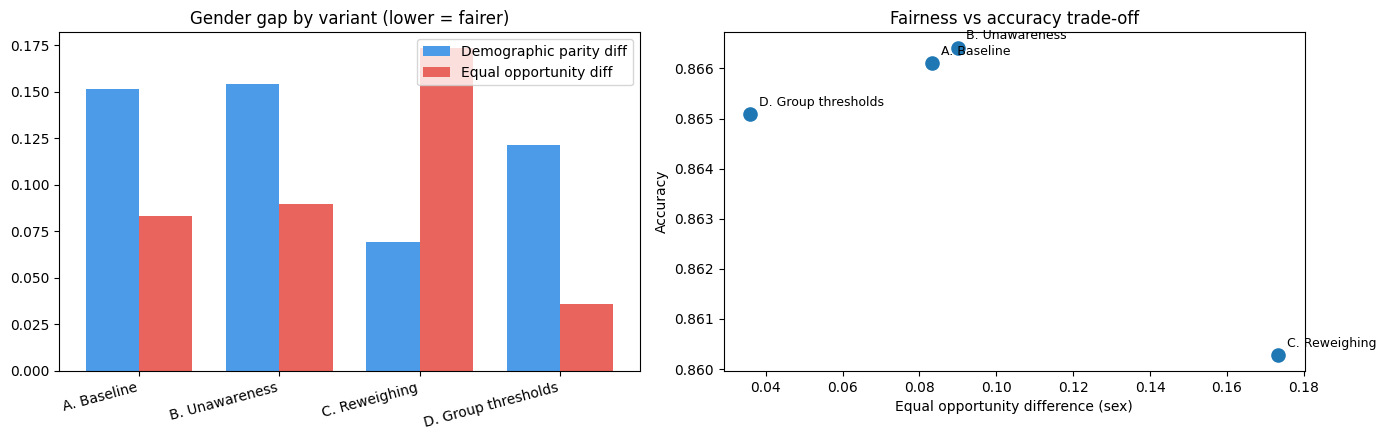

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(results.index); x = np.arange(len(names)); w = 0.38
ax[0].bar(x - w/2, results["Sex DP diff"], w, label="Demographic parity diff", color="#4c9be8")
ax[0].bar(x + w/2, results["Sex EO diff"], w, label="Equal opportunity diff", color="#e8645c")
ax[0].set_xticks(x); ax[0].set_xticklabels(names, rotation=15, ha="right"); ax[0].set_title("Gender gap by variant (lower = fairer)"); ax[0].legend()

ax[1].scatter(results["Sex EO diff"], results["Accuracy"], s=90)
for n, r in results.iterrows(): ax[1].annotate(n, (r["Sex EO diff"], r["Accuracy"]), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax[1].set_xlabel("Equal opportunity difference (sex)"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Fairness vs accuracy trade-off")
plt.tight_layout(); plt.savefig("mitigation_tradeoff.png", dpi=150); plt.show()

## 9. Discussion points
- **Different fairness definitions can conflict.** Demographic parity (equal selection rates) and equal opportunity (equal recall) cannot generally both be satisfied when the underlying base rates differ between groups.
- **A gap in predictions is not automatic proof of discrimination, and a small gap is not proof of fairness.** The training labels themselves (historic income) encode past inequality, so a model that predicts them accurately may reproduce it.
- **Group-specific thresholds use the sensitive attribute at decision time**, which may be unlawful or inappropriate in some domains (e.g. credit, hiring). It is shown here as a measurable technique, not a blanket recommendation.
- Fairness work should be re-run whenever the data, model or population changes.

## 10. Save results and generate the short write-up (`REPORT.md`)

In [15]:
def df_to_md(d, fmt="{:.3f}"):
    d = d.copy(); cols = [d.index.name or ""] + list(d.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, r in d.iterrows():
        out.append("| " + " | ".join([str(idx)] + [(fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)) for v in r.values]) + " |")
    return "\n".join(out)

def describe_gap(rep, col, fair):
    r = rep[rep["n"] >= MIN_N]
    hi, lo = r["selection_rate"].idxmax(), r["selection_rate"].idxmin()
    rule = "**below** the 0.80 four-fifths guideline" if fair["dp_ratio"] < 0.8 else "above the 0.80 four-fifths guideline"
    return (f"- **{col.capitalize()}:** {hi} are predicted >50K at {r.loc[hi, 'selection_rate']:.1%} vs {lo} at {r.loc[lo, 'selection_rate']:.1%} "
            f"(disparate-impact ratio {fair['dp_ratio']:.2f}, {rule}). The recall (TPR) gap is {fair['eo_diff']:.3f}: the model finds "
            f"{r.loc[r['TPR'].idxmax(), 'TPR']:.1%} of true high earners in group {r['TPR'].idxmax()} but only {r.loc[r['TPR'].idxmin(), 'TPR']:.1%} in group {r['TPR'].idxmin()}. "
            f"In the underlying data, {hi} have a >50K rate of {r.loc[hi, 'base_rate']:.1%} and {lo} {r.loc[lo, 'base_rate']:.1%}.")

best_eo = results["Sex EO diff"].idxmin()
base_row, best_row = results.loc["A. Baseline"], results.loc[best_eo]
top_feats = ", ".join(perm_imp.head(5).index)
sens_rank = {c: int(list(perm_imp.index).index(c)) + 1 for c in SENSITIVE}
shap_line = ""
if "shap_by_feature" in globals():
    shap_line = f"- SHAP global ranking (mean |SHAP|, top 5): {', '.join(shap_by_feature.head(5).index)}. See `shap_summary.png`, `shap_global_importance.png` and the three `shap_waterfall_*.png` plots for individual explanations.\n"

report = f'''# Responsible AI & Model Interpretation: Short Write-up

**Data:** {DATA_SOURCE} ({len(df):,} rows). **Model:** Random Forest predicting income >50K. **Sensitive attributes audited:** sex, race.
**Split:** 60% train / 20% validation / 20% test. All numbers below are from the held-out test set (n = {len(X_test):,}).
**Baseline performance:** accuracy {base_row["Accuracy"]:.3f}, F1 {base_row["F1"]:.3f}, ROC-AUC {base_row["ROC-AUC"]:.3f}.

## 1. Explainability
- Permutation importance (drop in ROC-AUC), top 5 features: **{top_feats}**.
- Rank of sensitive attributes in permutation importance: sex = #{sens_rank["sex"]}, race = #{sens_rank["race"]}.
{shap_line}- Local SHAP explanations show, for individual people, which features pushed the prediction towards or away from >50K.

## 2. Bias checks (baseline model)
{describe_gap(rep_sex, "sex", base_fair_sex)}
{describe_gap(rep_race, "race", base_fair_race)}

**By sex**

{df_to_md(rep_sex.rename_axis("group"))}

**By race** (groups with n < {MIN_N} are excluded from the gap metrics)

{df_to_md(rep_race.rename_axis("group"))}

**Fairness through unawareness:** removing sex and race changed the sex equal-opportunity gap from {base_fair_sex["eo_diff"]:.3f} to {unaware_fair_sex["eo_diff"]:.3f}. Sex can still be predicted from the remaining features with ROC-AUC {proxy_auc:.2f} (strongest proxies: {", ".join(proxy_top.index)}), so proxy information remains.

## 3. Mitigation results (test set)
{df_to_md(results.rename_axis("variant"))}

- The lowest sex equal-opportunity gap came from **{best_eo}**: {base_row["Sex EO diff"]:.3f} → {best_row["Sex EO diff"]:.3f}, with accuracy {base_row["Accuracy"]:.3f} → {best_row["Accuracy"]:.3f} (change {best_row["Accuracy"] - base_row["Accuracy"]:+.3f}).
- Demographic-parity difference (sex) for the same variant: {base_row["Sex DP diff"]:.3f} → {best_row["Sex DP diff"]:.3f}. Equalising recall does not necessarily equalise selection rates, because the groups' base rates differ.

## 4. Recommended mitigation steps
1. **Audit the data and labels first.** Check how each group was sampled and whether historic income reflects past inequality; collect more data for small groups (e.g. rare race categories give very noisy estimates).
2. **Don't rely on "just drop the sensitive column."** Proxies (relationship, marital status, occupation, hours) carry the same information; audit outcomes by group instead.
3. **Pre-processing:** apply reweighing (or resampling) during training; it needs no group information at prediction time.
4. **Post-processing:** where legally permitted, use group-aware thresholds tuned on validation data to equalise error rates; confirm legality and policy fit before deployment.
5. **Choose the fairness metric deliberately** with stakeholders (parity vs equal opportunity) and document the accuracy trade-off.
6. **Keep a human in the loop** for high-stakes decisions, offer explanations (SHAP) and a way to contest outcomes.
7. **Monitor and re-audit** fairness metrics regularly in production; publish a model card describing data, intended use, group metrics and known limitations.

## 5. Limitations
- The Adult dataset is a 1994 US Census extract; it is a teaching benchmark, not a basis for real decisions.
- Only binary sex and five coarse race categories are available; intersectional groups (e.g. Black women) were not analysed.
- Small groups yield noisy metrics; a single train/test split was used, so differences of about 1–2 points are within noise.
- This is a technical analysis; deciding what counts as "fair" for a real system is a policy and ethics decision.
'''
if DATA_SOURCE != "UCI Adult (OpenML)":
    report = "> WARNING: generated from SYNTHETIC stand-in data (dataset download failed). Re-run with internet access.\n\n" + report
open("REPORT.md", "w").write(report)

json.dump({"data_source": DATA_SOURCE, "baseline_fairness_sex": base_fair_sex, "baseline_fairness_race": base_fair_race,
           "variants": results.round(4).to_dict(orient="index"), "permutation_importance": perm_imp.round(5).to_dict(),
           "proxy_auc_sex": proxy_auc}, open("results.json", "w"), indent=2, default=float)
print("Saved REPORT.md and results.json")
print(report[:1500])

Saved REPORT.md and results.json
# Responsible AI & Model Interpretation: Short Write-up

**Data:** UCI Adult (OpenML) (48,842 rows). **Model:** Random Forest predicting income >50K. **Sensitive attributes audited:** sex, race.
**Split:** 60% train / 20% validation / 20% test. All numbers below are from the held-out test set (n = 9,769).
**Baseline performance:** accuracy 0.866, F1 0.672, ROC-AUC 0.920.

## 1. Explainability
- Permutation importance (drop in ROC-AUC), top 5 features: **marital-status, capital-gain, education-num, occupation, age**.
- Rank of sensitive attributes in permutation importance: sex = #9, race = #12.
- SHAP global ranking (mean |SHAP|, top 5): marital-status, relationship, education-num, occupation, capital-gain. See `shap_summary.png`, `shap_global_importance.png` and the three `shap_waterfall_*.png` plots for individual explanations.
- Local SHAP explanations show, for individual people, which features pushed the prediction towards or away from >50K.

## 2.